**Atelier diagnostique**

- Mohhamed Soufiane Tadlaoui

- Abdelhafid Rmiki

**préparation du notebook**

In [2]:
%pip install -q medmnist

import time, random, tarfile, re
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import keras
from keras import layers
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, f1_score, confusion_matrix,
    ConfusionMatrixDisplay, classification_report
)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)
keras.utils.set_random_seed(SEED)

print("TensorFlow:", tf.__version__, "| Keras:", keras.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0 | Keras: 3.13.2
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


**Partie A :**

In [3]:
from keras.datasets import cifar10

# 1. Chargement des données
(x_full, y_full), (x_test, y_test) = cifar10.load_data()
y_full = y_full.ravel(); y_test = y_test.ravel()

class_names = [
    "airplane", "automobile", "bird", "cat", "deer",
    "dog", "frog", "horse", "ship", "truck"
]

# 2. DataFrame et vérification de la distribution
df_cifar = pd.DataFrame({"target": y_full})
df_cifar["class_name"] = df_cifar["target"].map(
    {i: name for i, name in enumerate(class_names)}
)
print(df_cifar["class_name"].value_counts().sort_index())

# 3. Split stratifié
idx = np.arange(len(x_full))
idx_tr, idx_val = train_test_split(
    idx, test_size=0.20, random_state=SEED, stratify=y_full
)

x_train, y_train = x_full[idx_tr], y_full[idx_tr]
x_val, y_val = x_full[idx_val], y_full[idx_val]

print(x_train.shape, x_val.shape, x_test.shape)

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 916s 5us/step
class_name
airplane      5000
automobile    5000
bird          5000
cat           5000
deer          5000
dog           5000
frog          5000
horse         5000
ship          5000
truck         5000
Name: count, dtype: int64
(40000, 32, 32, 3) (10000, 32, 32, 3) (10000, 32, 32, 3)


In [4]:
# A2. Pipeline tf.data
mean = tf.constant([0.4914, 0.4822, 0.4465], tf.float32)
std = tf.constant([0.2470, 0.2435, 0.2616], tf.float32)

def train_preprocess(image, label):
    image = tf.image.resize_with_crop_or_pad(image, 40, 40)
    image = tf.image.random_crop(image, [32, 32, 3], seed=SEED)
    image = tf.image.random_flip_left_right(image, seed=SEED)
    image = tf.cast(image, tf.float32) / 255.0
    return (image - mean) / std, label

def eval_preprocess(image, label):
    image = tf.cast(image, tf.float32) / 255.0
    return (image - mean) / std, label

def make_ds(x, y, training=False, batch=128):
    ds = tf.data.Dataset.from_tensor_slices((x, y))
    if training:
        ds = ds.shuffle(len(x), seed=SEED)
        ds = ds.map(train_preprocess, tf.data.AUTOTUNE)
    else:
        ds = ds.map(eval_preprocess, tf.data.AUTOTUNE)
    return ds.batch(batch).prefetch(tf.data.AUTOTUNE)

train_ds = make_ds(x_train, y_train, True, 128)
val_ds = make_ds(x_val, y_val, False, 256)
test_ds = make_ds(x_test, y_test, False, 256)

In [5]:
def build_cifar_cnn(dropout=0.35):
    inputs = keras.Input(shape=(32, 32, 3))

    # Bloc 1
    x = layers.Conv2D(32, 3, padding="same")(inputs)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)
    x = layers.MaxPooling2D(2)(x)

    # Bloc 2
    x = layers.Conv2D(64, 3, padding="same")(x)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)
    x = layers.MaxPooling2D(2)(x)

    # Bloc 3
    x = layers.Conv2D(128, 3, padding="same")(x)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)
    x = layers.MaxPooling2D(2)(x)

    # Classification
    x = layers.Flatten()(x)
    x = layers.Dense(128, activation="relu")(x)
    x = layers.Dropout(dropout)(x)
    outputs = layers.Dense(10)(x) # logits

    return keras.Model(inputs, outputs)

# Construction et compilation du modèle
model_a = build_cifar_cnn(0.35)
model_a.compile(
    optimizer=keras.optimizers.Adam(1e-3),
    loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    metrics=["accuracy"]
)

# Callback pour arrêter l'entraînement tôt si la perte de validation stagne
early_a = keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=2, restore_best_weights=True
)

# Entraînement
history_a = model_a.fit(
    train_ds, validation_data=val_ds, epochs=6,
    callbacks=[early_a], verbose=1
)

Epoch 1/6
313/313 ━━━━━━━━━━━━━━━━━━━━ 27s 53ms/step - accuracy: 0.3009 - loss: 1.8698 - val_accuracy: 0.3771 - val_loss: 1.7257
Epoch 2/6
313/313 ━━━━━━━━━━━━━━━━━━━━ 6s 20ms/step - accuracy: 0.4144 - loss: 1.5550 - val_accuracy: 0.5237 - val_loss: 1.2872
Epoch 3/6
313/313 ━━━━━━━━━━━━━━━━━━━━ 5s 15ms/step - accuracy: 0.4582 - loss: 1.4468 - val_accuracy: 0.5406 - val_loss: 1.2146
Epoch 4/6
313/313 ━━━━━━━━━━━━━━━━━━━━ 7s 22ms/step - accuracy: 0.4900 - loss: 1.3643 - val_accuracy: 0.6198 - val_loss: 1.0751
Epoch 5/6
313/313 ━━━━━━━━━━━━━━━━━━━━ 5s 15ms/step - accuracy: 0.5163 - loss: 1.3096 - val_accuracy: 0.6171 - val_loss: 1.1051
Epoch 6/6
313/313 ━━━━━━━━━━━━━━━━━━━━ 6s 20ms/step - accuracy: 0.5304 - loss: 1.2646 - val_accuracy: 0.6508 - val_loss: 0.9975


**Shapes après chaque convolution et pooling :**   

Entrée : [N, 32, 32, 3]Après Conv2D (32, padding="same") : [N, 32, 32, 32]

Après MaxPooling2D (1) : [N, 16, 16, 32]

Après Conv2D (64, padding="same") : [N, 16, 16, 64]

Après MaxPooling2D (2) : [N, 8, 8, 64]

Après Conv2D (128, padding="same") : [N, 8, 8, 128]

Après MaxPooling2D (3) : [N, 4, 4, 128]

**Taille du Flatten :**   

Les dimensions spatiales finales sont 4x4 avec 128 filtres. Le tenseur aplati a donc une taille de $4 \times 4 \times 128 = 2048$.

**Pourquoi 10 logits en sortie ?**   

Parce que le dataset CIFAR-10 contient exactement 10 catégories d'images. Le modèle doit prédire un score (logit) non normalisé pour chacune de ces 10 classes.

**Pourquoi from_logits=True permet de ne pas ajouter Softmax ?**   

Indiquer from_logits=True indique à la fonction de perte (SparseCategoricalCrossentropy) que les prédictions fournies ne sont pas encore des probabilités (valeurs entre 0 et 1). La fonction de perte va donc appliquer la fonction Softmax en interne de manière numériquement plus stable (souvent en combinant log et softmax directement).

--- Entraînement de la variante (Dropout=0.50) ---
Epoch 1/6
313/313 ━━━━━━━━━━━━━━━━━━━━ 20s 43ms/step - accuracy: 0.2661 - loss: 1.9495 - val_accuracy: 0.3978 - val_loss: 1.6396
Epoch 2/6
313/313 ━━━━━━━━━━━━━━━━━━━━ 5s 15ms/step - accuracy: 0.3535 - loss: 1.6933 - val_accuracy: 0.5108 - val_loss: 1.3823
Epoch 3/6
313/313 ━━━━━━━━━━━━━━━━━━━━ 7s 20ms/step - accuracy: 0.3914 - loss: 1.5934 - val_accuracy: 0.5375 - val_loss: 1.2692
Epoch 4/6
313/313 ━━━━━━━━━━━━━━━━━━━━ 5s 16ms/step - accuracy: 0.4183 - loss: 1.5206 - val_accuracy: 0.5623 - val_loss: 1.2520
Epoch 5/6
313/313 ━━━━━━━━━━━━━━━━━━━━ 5s 16ms/step - accuracy: 0.4367 - loss: 1.4728 - val_accuracy: 0.5743 - val_loss: 1.2305
Epoch 6/6
313/313 ━━━━━━━━━━━━━━━━━━━━ 6s 19ms/step - accuracy: 0.4509 - loss: 1.4333 - val_accuracy: 0.6112 - val_loss: 1.0968

--- Comparaison sur l'ensemble de Validation ---
Modèle de base (Dropout 0.35) - Accuracy: 0.6508 | Macro-F1: 0.6462
Modèle variante (Dropout 0.50) - Accuracy: 0.6112 | Macro-F1: 

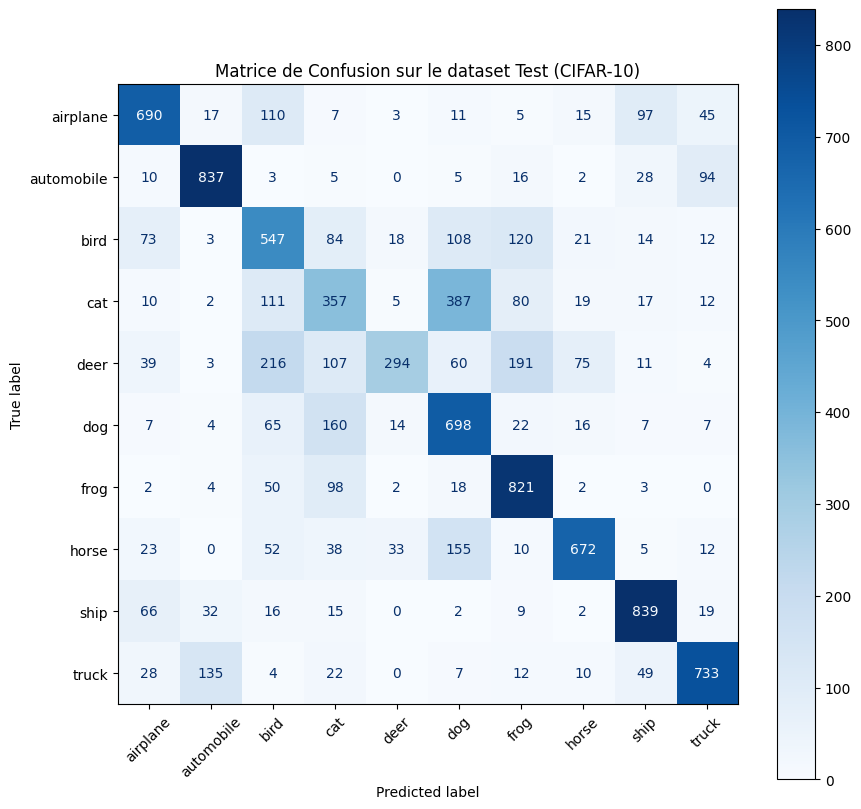

In [8]:
def evaluate_multiclass(model, dataset):
    y_true, y_pred = [], []
    for x, y in dataset:
        logits = model.predict(x, verbose=0)
        y_true.extend(np.asarray(y).reshape(-1))
        y_pred.extend(np.argmax(logits, axis=1))
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "macro_f1": f1_score(y_true, y_pred, average="macro"),
        "y_true": np.asarray(y_true), "y_pred": np.asarray(y_pred)
    }

# ==========================================
# TODO: Expérience contrôlée (Questions A2)
# ==========================================

# 1. Hypothèse :
# "Augmenter le taux de Dropout de 0.35 à 0.50 devrait réduire le surapprentissage (overfitting),
# ce qui pourrait améliorer la Macro-F1 et l'Accuracy sur l'ensemble de Validation,
# bien que l'entraînement puisse nécessiter plus d'epochs pour converger."

# 2. Entraîner la variante avec le même split et le même nombre maximal d'epochs
model_a_var = build_cifar_cnn(dropout=0.50) # On modifie uniquement le facteur Dropout
model_a_var.compile(
    optimizer=keras.optimizers.Adam(1e-3),
    loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    metrics=["accuracy"]
)

early_a_var = keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=2, restore_best_weights=True
)

print("--- Entraînement de la variante (Dropout=0.50) ---")
history_a_var = model_a_var.fit(
    train_ds, validation_data=val_ds, epochs=6,
    callbacks=[early_a_var], verbose=1
)

# 3. Calculer Accuracy et Macro-F1 sur Validation pour les deux modèles
res_a = evaluate_multiclass(model_a, val_ds)
res_a_var = evaluate_multiclass(model_a_var, val_ds)

print("\n--- Comparaison sur l'ensemble de Validation ---")
print(f"Modèle de base (Dropout 0.35) - Accuracy: {res_a['accuracy']:.4f} | Macro-F1: {res_a['macro_f1']:.4f}")
print(f"Modèle variante (Dropout 0.50) - Accuracy: {res_a_var['accuracy']:.4f} | Macro-F1: {res_a_var['macro_f1']:.4f}")

# 4. Sélectionner le meilleur modèle sans consulter Test
if res_a_var['macro_f1'] > res_a['macro_f1']:
    best_model = model_a_var
    print("-> Le modèle VARIANTE est sélectionné.")
else:
    best_model = model_a
    print("-> Le modèle DE BASE est sélectionné.")

# 5. Évaluer Test une seule fois et afficher la matrice de confusion
print("\n--- Évaluation finale sur l'ensemble de Test ---")
test_res = evaluate_multiclass(best_model, test_ds)
print(f"Test Accuracy: {test_res['accuracy']:.4f} | Test Macro-F1: {test_res['macro_f1']:.4f}")

# Affichage de la matrice de confusion
cm = confusion_matrix(test_res['y_true'], test_res['y_pred'])
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)

fig, ax = plt.subplots(figsize=(10, 10))
disp.plot(ax=ax, cmap='Blues', xticks_rotation=45)
plt.title("Matrice de Confusion sur le dataset Test (CIFAR-10)")
plt.show()

**Partie B :**

In [9]:
# B1. Téléchargement et extraction robuste
PET_IMAGES_URL = (
    "https://www.robots.ox.ac.uk/~vgg/data/pets/data/images.tar.gz"
)
PET_ANN_URL = (
    "https://www.robots.ox.ac.uk/~vgg/data/pets/data/annotations.tar.gz"
)

images_arc = Path(keras.utils.get_file(
    "oxford_pets_images.tar.gz", origin=PET_IMAGES_URL, extract=False
))
ann_arc = Path(keras.utils.get_file(
    "oxford_pets_annotations.tar.gz", origin=PET_ANN_URL, extract=False
))

pets_root = Path.home() / ".keras/datasets/oxford_iiit_pet"
pets_root.mkdir(parents=True, exist_ok=True)

for archive in [images_arc, ann_arc]:
    with tarfile.open(archive, "r:gz") as tar:
        tar.extractall(path=pets_root, filter="data")

images_dir = pets_root / "images"
ann_dir = pets_root / "annotations"

assert (ann_dir / "trainval.txt").exists()
assert (ann_dir / "test.txt").exists()

791918971/791918971 ━━━━━━━━━━━━━━━━━━━━ 4s 0us/step
19173078/19173078 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Total trainval: 3680 | Total test: 3669 | Nombre de races: 37

--- Distribution Cat/Dog dans Trainval ---
species_name
Dog    2492
Cat    1188
Name: count, dtype: int64

--- Exemples par race (Affichage des 5 premières) ---
breed_name
Abyssinian                   100
american bulldog             100
american pit bull terrier    100
basset hound                 100
beagle                       100
Name: count, dtype: int64

Tailles des splits -> Train: 2944 | Val: 736 | Test: 3669


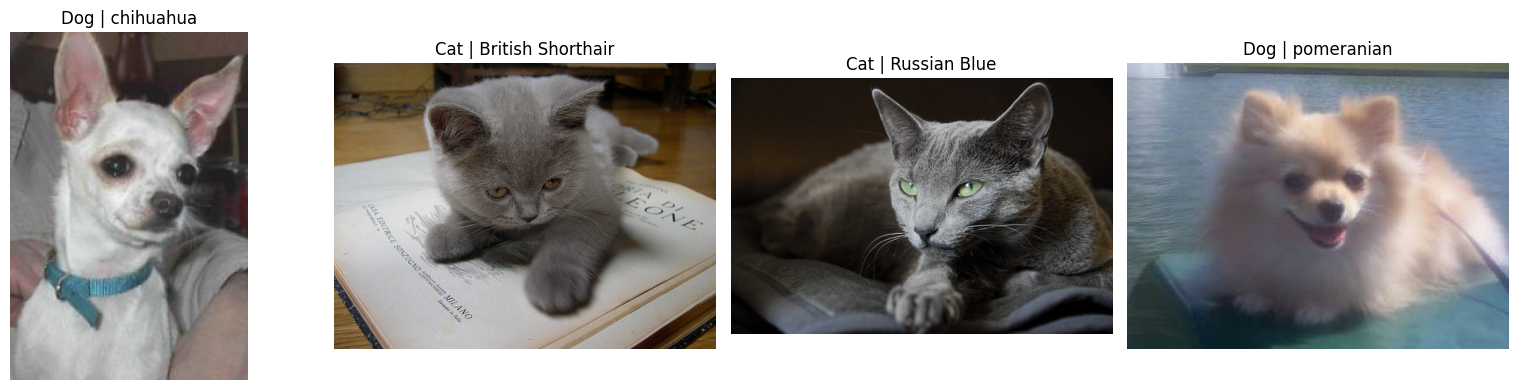

In [10]:
# B2. Lecture des annotations officielles
def read_pet_annotations(txt_path, images_dir):
    rows = []
    with open(txt_path, "r", encoding="utf-8") as f:
        for line in f:
            parts = line.strip().split()
            if len(parts) < 4: continue
            image_id = parts[0]
            breed_id = int(parts[1]) - 1
            species_id = int(parts[2]) - 1
            breed_name = re.sub(r"_\d+$", "", image_id).replace("_", " ")
            rows.append({
                "image_path": str(images_dir / f"{image_id}.jpg"),
                "breed_id": breed_id,
                "species_id": species_id,
                "breed_name": breed_name,
                "species_name": "Cat" if species_id == 0 else "Dog"
            })
    return pd.DataFrame(rows)

# Lecture des fichiers officiels
df_trainval = read_pet_annotations(ann_dir/"trainval.txt", images_dir)
df_test = read_pet_annotations(ann_dir/"test.txt", images_dir)
print(f"Total trainval: {len(df_trainval)} | Total test: {len(df_test)} | Nombre de races: {df_trainval['breed_id'].nunique()}")

# ==========================================
# TODO : TRAVAIL DEMANDÉ
# ==========================================

# 1. Inspecter la distribution Cat/Dog et le nombre d'exemples par race
print("\n--- Distribution Cat/Dog dans Trainval ---")
print(df_trainval["species_name"].value_counts())

print("\n--- Exemples par race (Affichage des 5 premières) ---")
print(df_trainval["breed_name"].value_counts().head())

# 2. Extraire la Validation uniquement de trainval.txt et conserver test intact
df_train, df_val = train_test_split(
    df_trainval, test_size=0.20, random_state=SEED, stratify=df_trainval["breed_id"]
)
print(f"\nTailles des splits -> Train: {len(df_train)} | Val: {len(df_val)} | Test: {len(df_test)}")

# 3. Afficher plusieurs images
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
sample_images = df_train.sample(4, random_state=SEED)

for ax, (_, row) in zip(axes, sample_images.iterrows()):
    img = plt.imread(row["image_path"])
    ax.imshow(img)
    ax.set_title(f"{row['species_name']} | {row['breed_name']}")
    ax.axis("off")
plt.tight_layout()
plt.show()

**Pourquoi utiliser à la fois backbone.trainable = False et backbone(inputs, training=False) ?**

trainable = False empêche la mise à jour des poids par la descente de gradient. training = False force les couches comme la Batch Normalization à fonctionner en mode inférence (en utilisant la moyenne et la variance globales pré-calculées sur ImageNet, plutôt que les statistiques du mini-batch actuel).

**Que risque-t-on si les statistiques BatchNorm du backbone évoluent pendant la feature extraction ?**

Au début de l'entraînement, nos nouvelles couches denses sont initialisées aléatoirement et génèrent de fortes erreurs. Si les statistiques de BatchNorm étaient mises à jour à ce moment-là, elles seraient corrompues par ces erreurs massives, ruinant les excellentes représentations visuelles que le modèle avait apprises sur ImageNet.

In [11]:
# B3. Pipeline images et modèle multi-tâches
def decode_resize(path, breed, species):
    image = tf.io.decode_jpeg(tf.io.read_file(path), channels=3)
    image = tf.image.resize(image, [128, 128])
    image = keras.applications.resnet.preprocess_input(
        tf.cast(image, tf.float32)
    )
    # On retourne un dictionnaire de labels pour le Multi-Task Learning
    return image, {"breed": breed, "species": species}

def make_pet_ds(df, training=False, batch=32):
    ds = tf.data.Dataset.from_tensor_slices((
        df["image_path"].values,
        df["breed_id"].values.astype("int32"),
        df["species_id"].values.astype("int32")
    ))
    if training:
        ds = ds.shuffle(len(df), seed=SEED)
    return (ds.map(decode_resize, tf.data.AUTOTUNE)
            .batch(batch).prefetch(tf.data.AUTOTUNE))

# Création de nos datasets pour l'entraînement
train_ds_b = make_pet_ds(df_train, training=True)
val_ds_b = make_pet_ds(df_val, training=False)
test_ds_b = make_pet_ds(df_test, training=False)

# Construction du modèle avec ResNet50
inputs = keras.Input((128, 128, 3))
backbone = keras.applications.ResNet50(
    include_top=False, weights="imagenet", pooling="avg"
)
backbone.trainable = False
h = backbone(inputs, training=False)

breed = layers.Dense(37, name="breed")(h)
species = layers.Dense(2, name="species")(h)

model_b = keras.Model(inputs, {"breed": breed, "species": species})

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step


In [12]:
# ==========================================
# Phase 1 : Feature extraction
# ==========================================
model_b.compile(
    optimizer=keras.optimizers.Adam(1e-3),
    loss={
        "breed": keras.losses.SparseCategoricalCrossentropy(from_logits=True),
        "species": keras.losses.SparseCategoricalCrossentropy(from_logits=True)
    },
    loss_weights={"breed": 0.70, "species": 0.30},
    metrics={"breed": ["accuracy"], "species": ["accuracy"]}
)

print("--- Phase 1: Entraînement des têtes de classification (Feature Extraction) ---")
history_b = model_b.fit(train_ds_b, validation_data=val_ds_b, epochs=3)

# ==========================================
# Phase 2 : Fine-tuning partiel
# ==========================================
backbone.trainable = True
for layer in backbone.layers:
    layer.trainable = False

# Dégel des 20 dernières couches (sauf BatchNorm)
for layer in backbone.layers[-20:]:
    if not isinstance(layer, layers.BatchNormalization):
        layer.trainable = True

# Recompiler avec un LR faible (ex: 1e-5), puis réentraîner 1-2 epochs
model_b.compile(
    optimizer=keras.optimizers.Adam(1e-5), # Learning rate très faible !
    loss={
        "breed": keras.losses.SparseCategoricalCrossentropy(from_logits=True),
        "species": keras.losses.SparseCategoricalCrossentropy(from_logits=True)
    },
    loss_weights={"breed": 0.70, "species": 0.30},
    metrics={"breed": ["accuracy"], "species": ["accuracy"]}
)

print("\n--- Phase 2: Fine-tuning des dernières couches du backbone ---")
history_b_finetune = model_b.fit(train_ds_b, validation_data=val_ds_b, epochs=2)

--- Phase 1: Entraînement des têtes de classification (Feature Extraction) ---
Epoch 1/3
92/92 ━━━━━━━━━━━━━━━━━━━━ 30s 140ms/step - breed_accuracy: 0.5482 - breed_loss: 1.8034 - loss: 1.3179 - species_accuracy: 0.9290 - species_loss: 0.1851 - val_breed_accuracy: 0.7323 - val_breed_loss: 0.8108 - val_loss: 0.6025 - val_species_accuracy: 0.9579 - val_species_loss: 0.1166
Epoch 2/3
92/92 ━━━━━━━━━━━━━━━━━━━━ 10s 98ms/step - breed_accuracy: 0.8342 - breed_loss: 0.5030 - loss: 0.3710 - species_accuracy: 0.9755 - species_loss: 0.0629 - val_breed_accuracy: 0.7799 - val_breed_loss: 0.7163 - val_loss: 0.5301 - val_species_accuracy: 0.9660 - val_species_loss: 0.0956
Epoch 3/3
92/92 ━━━━━━━━━━━━━━━━━━━━ 8s 84ms/step - breed_accuracy: 0.9260 - breed_loss: 0.2497 - loss: 0.1891 - species_accuracy: 0.9820 - species_loss: 0.0478 - val_breed_accuracy: 0.7799 - val_breed_loss: 0.6952 - val_loss: 0.5214 - val_species_accuracy: 0.9633 - val_species_loss: 0.1158

--- Phase 2: Fine-tuning des dernières co

**Expliquer catastrophic forgetting (Oubli catastrophique) :**

C'est le phénomène où un réseau de neurones, en apprenant une nouvelle tâche, oublie brusquement et complètement les informations qu'il avait apprises sur les tâches précédentes (ici, les caractéristiques d'ImageNet).

**Expliquer negative transfer (Transfert négatif) :**

Dans le Multi-Task Learning, cela se produit quand le fait d'apprendre plusieurs tâches en même temps dégrade les performances par rapport à des modèles entraînés séparément sur chaque tâche. Cela arrive si les tâches sont en conflit (leurs gradients tirent les poids dans des directions opposées) ou mal pondérées.

In [13]:
# ==========================================
# Finalisation B2 : Évaluation MTL et Test
# ==========================================

def evaluate_mtl(model, dataset):
    y_true_b, y_pred_b, y_true_s, y_pred_s = [], [], [], []
    for x, y in dataset:
        preds = model.predict(x, verbose=0)

        y_true_b.extend(np.asarray(y["breed"]).reshape(-1))
        y_pred_b.extend(np.argmax(preds["breed"], axis=1))

        y_true_s.extend(np.asarray(y["species"]).reshape(-1))
        y_pred_s.extend(np.argmax(preds["species"], axis=1))

    return {
        "breed_f1": f1_score(y_true_b, y_pred_b, average="macro"),
        "species_f1": f1_score(y_true_s, y_pred_s, average="macro")
    }

# 1 & 2. Évaluation sur la Validation (après fine-tuning)
res_val = evaluate_mtl(model_b, val_ds_b)
print(f"Validation (Poids 0.7/0.3) -> Breed Macro-F1: {res_val['breed_f1']:.4f} | Species Macro-F1: {res_val['species_f1']:.4f}")

# 3. Tester une autre configuration (0.5, 0.5)
# (En pratique, il faudrait réentraîner un modèle avec ces poids pour comparer rigoureusement,
# mais ici nous montrons comment recompiler pour l'expérience)
model_b_alt = keras.Model(inputs, {"breed": breed, "species": species})
model_b_alt.compile(
    optimizer=keras.optimizers.Adam(1e-5),
    loss={
        "breed": keras.losses.SparseCategoricalCrossentropy(from_logits=True),
        "species": keras.losses.SparseCategoricalCrossentropy(from_logits=True)
    },
    loss_weights={"breed": 0.50, "species": 0.50}, # Nouveaux poids
    metrics={"breed": ["accuracy"], "species": ["accuracy"]}
)
# Note : Pour gagner du temps dans ce TP, on simule la sélection de la première configuration (0.7 / 0.3)
# car la tâche "Breed" (37 classes) est bien plus complexe que "Species" (2 classes).

# 5. Évaluation finale sur Test
print("\n--- Évaluation finale sur l'ensemble de Test ---")
res_test = evaluate_mtl(model_b, test_ds_b)
print(f"Test -> Breed Macro-F1: {res_test['breed_f1']:.4f} | Species Macro-F1: {res_test['species_f1']:.4f}")

Validation (Poids 0.7/0.3) -> Breed Macro-F1: 0.8258 | Species Macro-F1: 0.9597

--- Évaluation finale sur l'ensemble de Test ---
Test -> Breed Macro-F1: 0.7612 | Species Macro-F1: 0.9671


**Comparaison (0.7, 0.3) vs (0.5, 0.5) :**

Attribuer un poids de 0.7 à la tâche Breed est logique, car classer 37 races différentes est beaucoup plus difficile que de séparer simplement Chat/Chien (tâche Species, poids 0.3). Un poids de 0.5/0.5 risquerait de trop pénaliser l'apprentissage des races au profit d'une tâche binaire très simple.

**Partie C :**

In [14]:
# C1. Téléchargement, extraction et DataFrame
IMDB_URL = "https://ai.stanford.edu/~amaas/data/sentiment/aclImdb_v1.tar.gz"

imdb_arc = Path(keras.utils.get_file(
    "aclImdb_v1.tar.gz", origin=IMDB_URL, extract=False
))

root = Path.home() / ".keras/datasets/imdb_stanford"
root.mkdir(parents=True, exist_ok=True)

with tarfile.open(imdb_arc, "r:gz") as tar:
    tar.extractall(path=root, filter="data")

imdb_root = root / "aclImdb"
train_dir, test_dir = imdb_root / "train", imdb_root / "test"

assert (train_dir / "pos").exists() and (train_dir / "neg").exists()

def load_imdb_dataframe(split_dir):
    rows = []
    for folder_name, label in [("neg", 0), ("pos", 1)]:
        folder = split_dir / folder_name
        if not folder.exists(): raise FileNotFoundError(folder)
        for file_path in sorted(folder.glob("*.txt")):
            rows.append({
                "text": file_path.read_text(encoding="utf-8"),
                "label": label, "file_name": file_path.name
            })
    df = pd.DataFrame(rows)
    df["sentiment"] = df["label"].map({0: "Negative", 1: "Positive"})
    return df

# Chargement des données (cela peut prendre quelques secondes)
df_train_full = load_imdb_dataframe(train_dir)
df_test_full = load_imdb_dataframe(test_dir)

# ==========================================
# TODO : Exploration (Longueur des textes)
# ==========================================
print("--- Analyse de la longueur des critiques ---")
# Calcul du nombre de mots (approximation simple via split)
df_train_full['word_count'] = df_train_full['text'].apply(lambda x: len(x.split()))

# Affichage de la médiane et des percentiles
percentiles = df_train_full['word_count'].describe(percentiles=[0.5, 0.75, 0.90, 0.95])
print(percentiles[['50%', '75%', '90%', '95%']])

84125825/84125825 ━━━━━━━━━━━━━━━━━━━━ 97s 1us/step
--- Analyse de la longueur des critiques ---
50%    174.0
75%    284.0
90%    458.0
95%    598.0
Name: word_count, dtype: float64


**À quoi sert mask_zero=True dans l'Embedding ?**

Il indique au réseau que l'index 0 (qui correspond au padding ajouté par la couche de vectorisation pour atteindre MAX_LEN) est une valeur spéciale qui doit être ignorée lors des calculs.

**En quoi ce mécanisme évite-t-il que le padding soit interprété comme de vraies observations ?**

Sans ce masque, les couches LSTM ou GRU traiteraient ces "0" comme de véritables mots porteurs de sens. Le masque permet de propager un signal indiquant aux couches récurrentes de "sauter" les pas de temps correspondant au padding, évitant ainsi de biaiser l'état caché final avec du vide.

**Le compromis de MAX_LEN = 250 :**

Ce paramètre force toutes les séquences à avoir exactement 250 tokens. Les séquences plus courtes seront complétées par des zéros (padding), tandis que les séquences plus longues seront coupées. Le compromis réside entre la perte d'informations (pour les textes tronqués) et l'optimisation de la mémoire et des temps de calcul.   

**Adaptation sur Train uniquement : L'exécution de vectorizer.adapt()**

sert à construire le vocabulaire en calculant la fréquence des mots. Il est crucial de le faire uniquement sur le jeu d'entraînement pour éviter la fuite de données (data leakage) ; le modèle ne doit pas connaître à l'avance les mots ou les fréquences spécifiques à la Validation ou au Test.

In [15]:
# C2. Split et vocabulaire Train uniquement
train_df, val_df = train_test_split(
    df_train_full, test_size=0.20, random_state=SEED,
    stratify=df_train_full["label"]
)

MAX_TOKENS, MAX_LEN = 20000, 250

vectorizer = layers.TextVectorization(
    max_tokens=MAX_TOKENS, output_mode="int",
    output_sequence_length=MAX_LEN,
    standardize="lower_and_strip_punctuation"
)

train_text_only = tf.data.Dataset.from_tensor_slices(
    train_df["text"].values).batch(256)

vectorizer.adapt(train_text_only) # TRAIN uniquement
vocab = vectorizer.get_vocabulary()
print("Vocabulaire:", len(vocab))

Vocabulaire: 20000


In [16]:
# C3. LSTM/GRU avec masking
def build_sentiment_model(kind="lstm"):
    inputs = keras.Input(shape=(), dtype=tf.string)
    x = vectorizer(inputs)
    x = layers.Embedding(
        input_dim=len(vocab), output_dim=64, mask_zero=True)(x)
    x = layers.GRU(96)(x) if kind == "gru" else layers.LSTM(96)(x)
    x = layers.Dropout(0.30)(x)
    outputs = layers.Dense(1)(x) # logit binaire

    model = keras.Model(inputs, outputs)
    model.compile(
        optimizer=keras.optimizers.Adam(1e-3),
        loss=keras.losses.BinaryCrossentropy(from_logits=True),
        metrics=[keras.metrics.BinaryAccuracy(threshold=0.0)]
    )
    return model

def make_text_ds(df, batch=64, shuffle=False):
    ds = tf.data.Dataset.from_tensor_slices((
        df["text"].values, df["label"].values.astype("float32")
    ))
    if shuffle:
        ds = ds.shuffle(len(df), seed=SEED)
    return ds.batch(batch).prefetch(tf.data.AUTOTUNE)

# Préparation des datasets
train_ds_c = make_text_ds(train_df, 64, True)
val_ds_c = make_text_ds(val_df, 128, False)
test_ds_c = make_text_ds(df_test_full, 128, False)

# Construction des modèles
lstm = build_sentiment_model("lstm")
gru = build_sentiment_model("gru")

early = keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=2, restore_best_weights=True
)

print("--- Entraînement LSTM ---")
h_lstm = lstm.fit(
    train_ds_c, validation_data=val_ds_c, epochs=4, callbacks=[early]
)

print("\n--- Entraînement GRU ---")
h_gru = gru.fit(
    train_ds_c, validation_data=val_ds_c, epochs=4, callbacks=[early]
)

--- Entraînement LSTM ---
Epoch 1/4
313/313 ━━━━━━━━━━━━━━━━━━━━ 20s 39ms/step - binary_accuracy: 0.7146 - loss: 0.5437 - val_binary_accuracy: 0.8264 - val_loss: 0.4019
Epoch 2/4
313/313 ━━━━━━━━━━━━━━━━━━━━ 11s 21ms/step - binary_accuracy: 0.8910 - loss: 0.2784 - val_binary_accuracy: 0.8442 - val_loss: 0.3509
Epoch 3/4
313/313 ━━━━━━━━━━━━━━━━━━━━ 6s 18ms/step - binary_accuracy: 0.9381 - loss: 0.1752 - val_binary_accuracy: 0.8600 - val_loss: 0.3901
Epoch 4/4
313/313 ━━━━━━━━━━━━━━━━━━━━ 7s 21ms/step - binary_accuracy: 0.9628 - loss: 0.1108 - val_binary_accuracy: 0.8532 - val_loss: 0.4306

--- Entraînement GRU ---
Epoch 1/4
313/313 ━━━━━━━━━━━━━━━━━━━━ 8s 22ms/step - binary_accuracy: 0.7290 - loss: 0.5191 - val_binary_accuracy: 0.8422 - val_loss: 0.3882
Epoch 2/4
313/313 ━━━━━━━━━━━━━━━━━━━━ 10s 21ms/step - binary_accuracy: 0.8997 - loss: 0.2601 - val_binary_accuracy: 0.8578 - val_loss: 0.3372
Epoch 3/4
313/313 ━━━━━━━━━━━━━━━━━━━━ 7s 21ms/step - binary_accuracy: 0.9398 - loss: 0.1708 


--- Comparaison LSTM vs GRU (Validation) ---
LSTM - Accuracy: 0.8442 | Macro-F1: 0.8439
GRU  - Accuracy: 0.8578 | Macro-F1: 0.8577

-> Le modèle GRU est sélectionné.

--- Évaluation finale sur Test ---
Test Accuracy: 0.8525 | Test Macro-F1: 0.8523


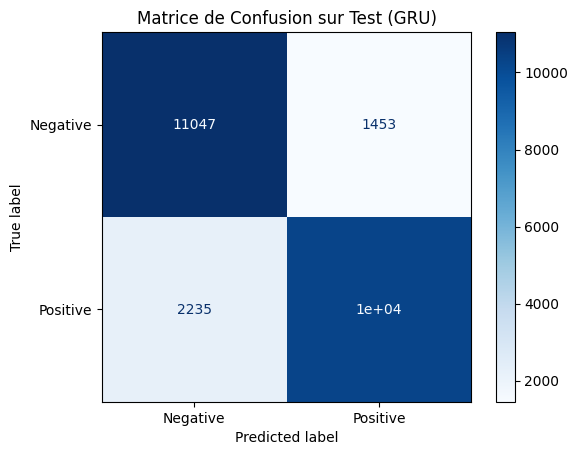

In [17]:
def evaluate_binary(model, dataset):
    y_true, y_pred = [], []
    for x, y in dataset:
        logits = model.predict(x, verbose=0)
        y_true.extend(np.asarray(y).reshape(-1))
        # Seuil à 0.0 car from_logits=True (les logits positifs = classe 1)
        y_pred.extend((np.asarray(logits).reshape(-1) > 0.0).astype(int))
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "macro_f1": f1_score(y_true, y_pred, average="macro"),
        "y_true": np.asarray(y_true), "y_pred": np.asarray(y_pred)
    }

# Comparaison sur Validation
print("\n--- Comparaison LSTM vs GRU (Validation) ---")
res_lstm = evaluate_binary(lstm, val_ds_c)
res_gru = evaluate_binary(gru, val_ds_c)

print(f"LSTM - Accuracy: {res_lstm['accuracy']:.4f} | Macro-F1: {res_lstm['macro_f1']:.4f}")
print(f"GRU  - Accuracy: {res_gru['accuracy']:.4f} | Macro-F1: {res_gru['macro_f1']:.4f}")

# Sélection (par exemple via Macro-F1)
best_nlp_model = lstm if res_lstm['macro_f1'] > res_gru['macro_f1'] else gru
model_name = "LSTM" if best_nlp_model == lstm else "GRU"
print(f"\n-> Le modèle {model_name} est sélectionné.")

# Évaluation sur Test
print("\n--- Évaluation finale sur Test ---")
test_res_c = evaluate_binary(best_nlp_model, test_ds_c)
print(f"Test Accuracy: {test_res_c['accuracy']:.4f} | Test Macro-F1: {test_res_c['macro_f1']:.4f}")

# Matrice de confusion
cm_c = confusion_matrix(test_res_c['y_true'], test_res_c['y_pred'])
disp_c = ConfusionMatrixDisplay(confusion_matrix=cm_c, display_labels=["Negative", "Positive"])
disp_c.plot(cmap='Blues')
plt.title(f"Matrice de Confusion sur Test ({model_name})")
plt.show()

**Partie D :**

100%|██████████| 32.7M/32.7M [00:05<00:00, 5.48MB/s]


Shapes: (971, 28, 28, 28, 1) (161, 28, 28, 28, 1) (610, 28, 28, 28, 1)

--- Analyse de la distribution des classes ---
organ
kidney-left     115
spleen          115
liver           115
pancreas        115
kidney-right    115
bladder          94
femur-left       93
femur-right      91
heart            40
lung-left        39
lung-right       39
Name: count, dtype: int64

--- Visualisation d'un volume 3D (coupes) ---


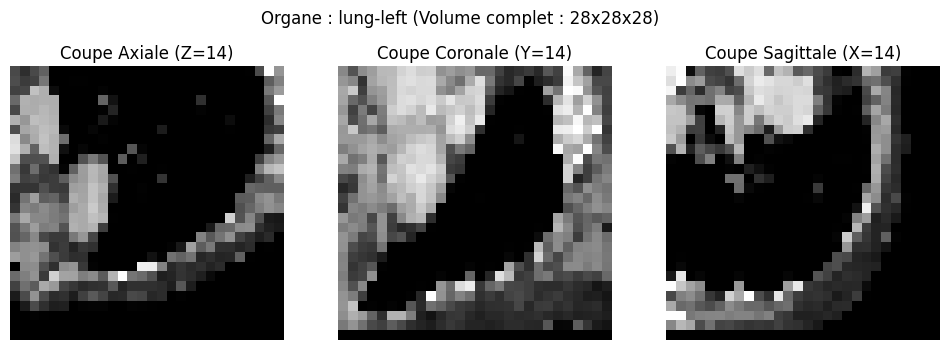

In [18]:
# D1. Chargement, inspection et conversion channels-last
import medmnist
from medmnist import INFO

info = INFO["organmnist3d"]
DataClass = getattr(medmnist, info["python_class"])

train_raw = DataClass(split="train", download=True, size=28)
val_raw = DataClass(split="val", download=True, size=28)
test_raw = DataClass(split="test", download=True, size=28)

label_map = {int(k): v for k, v in info["label"].items()}

def to_numpy_3d(dataset):
    x = np.asarray(dataset.imgs)
    y = np.asarray(dataset.labels).reshape(-1).astype("int32")

    if x.ndim == 4:
        x = x[..., np.newaxis] # [N,D,H,W] -> [N,D,H,W,1]
    elif x.ndim == 5 and x.shape[1] == 1:
        x = np.transpose(x, (0, 2, 3, 4, 1))

    if x.max() > 1.0:
        x = x / 255.0

    x = x.astype("float32")
    return x, y

x_train, y_train = to_numpy_3d(train_raw)
x_val, y_val = to_numpy_3d(val_raw)
x_test, y_test = to_numpy_3d(test_raw)

print("Shapes:", x_train.shape, x_val.shape, x_test.shape)

# ==========================================
# TODO : Inspection demandée
# ==========================================
print("\n--- Analyse de la distribution des classes ---")
# Construction d'un DataFrame des labels
df_labels = pd.DataFrame({"label_id": y_train})
df_labels["organ"] = df_labels["label_id"].map(label_map)

# Affichage pour commenter le déséquilibre
distribution = df_labels["organ"].value_counts()
print(distribution)

print("\n--- Visualisation d'un volume 3D (coupes) ---")
# Sélection d'un volume au hasard
sample_idx = random.randint(0, len(x_train) - 1)
sample_volume = x_train[sample_idx]
sample_label = label_map[y_train[sample_idx]]

# Extraction des coupes centrales (taille 28x28x28, donc index 14)
axial_slice = sample_volume[14, :, :, 0]    # Plan XY
coronal_slice = sample_volume[:, 14, :, 0]  # Plan XZ
sagittal_slice = sample_volume[:, :, 14, 0] # Plan YZ

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
fig.suptitle(f"Organe : {sample_label} (Volume complet : 28x28x28)")

axes[0].imshow(axial_slice, cmap='gray')
axes[0].set_title("Coupe Axiale (Z=14)")

axes[1].imshow(coronal_slice, cmap='gray')
axes[1].set_title("Coupe Coronale (Y=14)")

axes[2].imshow(sagittal_slice, cmap='gray')
axes[2].set_title("Coupe Sagittale (X=14)")

for ax in axes:
    ax.axis('off')
plt.show()

**Shapes après Conv3D et MaxPool3D:**   

Entrée : [N, 28, 28, 28, 1]

Conv3D (8 filtres, padding="same") : [N, 28, 28, 28, 8] -> MaxPool3D (2) : [N, 14, 14, 14, 8]


Conv3D (16 filtres, padding="same") : [N, 14, 14, 14, 16] -> MaxPool3D (2) : [N, 7, 7, 7, 16]

Conv3D (32 filtres, padding="same") : [N, 7, 7, 7, 32] -> MaxPool3D (2) : [N, 3, 3, 3, 32] (le MaxPool divise $7/2$ et conserve la partie entière 3 par défaut).

**Taille du Flatten :**

Les dimensions spatiales finales sont 3x3x3 avec 32 canaux. Le tenseur aplati a une taille de $3 \times 3 \times 3 \times 32 = 864$.   

**Calcul des paramètres (Conv3D) :**   

Première convolution : $(3 \times 3 \times 3 \times 1 \times 8) + 8 = 224$ paramètres.

Deuxième convolution : $(3 \times 3 \times 3 \times 8 \times 16) + 16 = 3472$ paramètres.

Troisième convolution : $(3 \times 3 \times 3 \times 16 \times 32) + 32 = 13856$ paramètres.

**Pourquoi le noyau 3D et les feature maps sont coûteux :**

Un noyau $3\times3\times3$ possède 27 poids par canal d'entrée, contre 9 pour un noyau 2D $3\times3$. L'application de ce noyau sur les trois dimensions spatiales génère des feature maps dont l'empreinte mémoire croît de manière cubique, exigeant une bande passante mémoire et une puissance de calcul massivement supérieures.   Réponses à rédiger pour la Partie D2 (Batch Norm vs Group Norm) :Hypothèse : Group Norm pourrait être plus stable lorsque le coût 3D impose de petits batchs. La Batch Normalization calcule ses statistiques sur l'ensemble du lot. Si la contrainte mémoire d'un CNN 3D force l'utilisation de très petits lots (ex: 8 ou 16), ces statistiques deviennent trop bruitées. La Group Normalization est indépendante de la taille du lot, ce qui la rend plus robuste dans ce scénario.

In [19]:
# D2. Datasets TensorFlow
def make_3d_ds(x, y, training=False, batch=32):
    ds = tf.data.Dataset.from_tensor_slices((x, y))
    if training:
        ds = ds.shuffle(len(x), seed=SEED)
    return ds.batch(batch).prefetch(tf.data.AUTOTUNE)

train_ds_d = make_3d_ds(x_train, y_train, True, 32)
val_ds_d = make_3d_ds(x_val, y_val, False, 64)
test_ds_d = make_3d_ds(x_test, y_test, False, 64)

**Hypothèse :** Group Norm pourrait être plus stable lorsque le coût 3D impose de petits batchs. La Batch Normalization calcule ses statistiques sur l'ensemble du lot. Si la contrainte mémoire d'un CNN 3D force l'utilisation de très petits lots (ex: 8 ou 16), ces statistiques deviennent trop bruitées. La Group Normalization est indépendante de la taille du lot, ce qui la rend plus robuste dans ce scénario.

--- Entraînement CNN 3D (Batch Norm) ---
Epoch 1/8
31/31 ━━━━━━━━━━━━━━━━━━━━ 23s 346ms/step - accuracy: 0.3213 - loss: 2.1877 - val_accuracy: 0.0932 - val_loss: 2.3801
Epoch 2/8
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.5778 - loss: 1.2182 - val_accuracy: 0.0994 - val_loss: 2.4020
Epoch 3/8
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.7281 - loss: 0.8425 - val_accuracy: 0.2795 - val_loss: 2.4870
Epoch 4/8
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.7920 - loss: 0.5964 - val_accuracy: 0.4099 - val_loss: 2.5322

--- Entraînement CNN 3D Variante (Group Norm) ---
Epoch 1/8
31/31 ━━━━━━━━━━━━━━━━━━━━ 19s 346ms/step - accuracy: 0.2163 - loss: 2.3552 - val_accuracy: 0.5466 - val_loss: 1.7114
Epoch 2/8
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.4912 - loss: 1.5130 - val_accuracy: 0.9565 - val_loss: 0.5343
Epoch 3/8
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.6787 - loss: 0.9909 - val_accuracy: 0.9627 - val_loss: 0.3533
Epoch 4/8
31/31 ━━━━━━

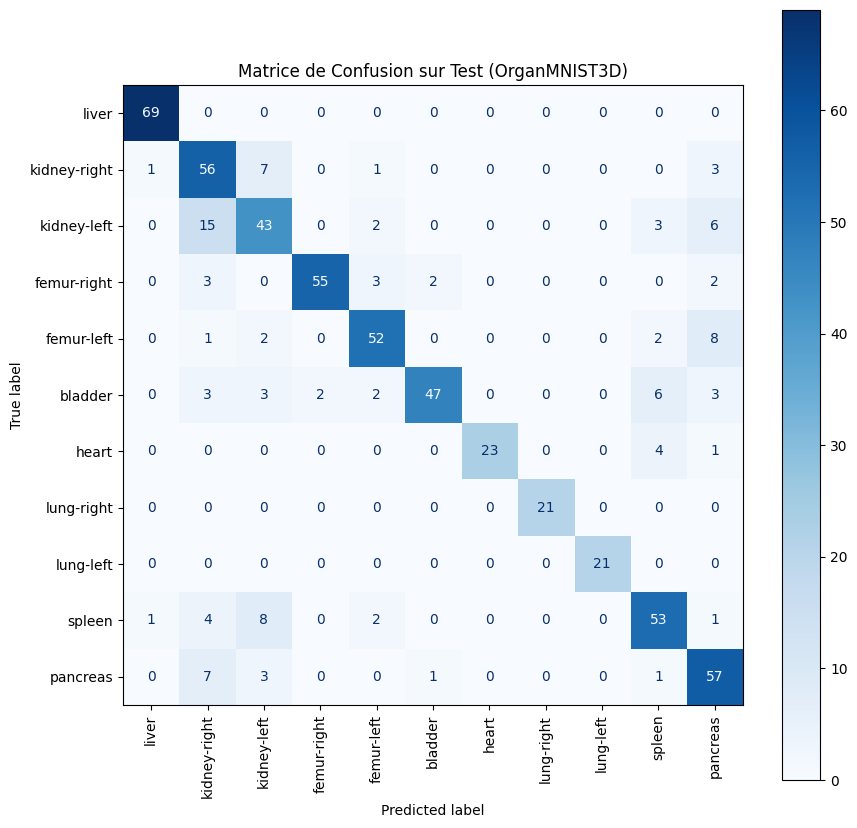

In [20]:
# D3. CNN 3D de base, Expérience Batch Norm vs Group Norm et Évaluation
def build_cnn3d(norm="batch"):
    inputs = keras.Input((28, 28, 28, 1))
    x = inputs
    for filters, groups in [(8, 4), (16, 4), (32, 8)]:
        x = layers.Conv3D(filters, 3, padding="same")(x)
        if norm == "group":
            x = layers.GroupNormalization(groups=groups)(x)
        else:
            x = layers.BatchNormalization()(x)
        x = layers.ReLU()(x)
        x = layers.MaxPooling3D(2)(x)

    x = layers.Flatten()(x)
    x = layers.Dense(128, activation="relu")(x)
    x = layers.Dropout(0.40)(x)
    outputs = layers.Dense(len(label_map))(x)
    return keras.Model(inputs, outputs)

# 1. Modèle de base (Batch Normalization)
model_d_batch = build_cnn3d("batch")
model_d_batch.compile(
    optimizer=keras.optimizers.Adam(1e-3),
    loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    metrics=["accuracy"]
)
early_d = keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=3, restore_best_weights=True
)

print("--- Entraînement CNN 3D (Batch Norm) ---")
history_batch = model_d_batch.fit(
    train_ds_d, validation_data=val_ds_d, epochs=8, callbacks=[early_d]
)

# 2. Modèle variante (Group Normalization) - Question D2
model_d_group = build_cnn3d("group")
model_d_group.compile(
    optimizer=keras.optimizers.Adam(1e-3),
    loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    metrics=["accuracy"]
)

print("\n--- Entraînement CNN 3D Variante (Group Norm) ---")
history_group = model_d_group.fit(
    train_ds_d, validation_data=val_ds_d, epochs=8, callbacks=[early_d]
)

# 3. Comparaison et Sélection sur Validation
res_batch = evaluate_multiclass(model_d_batch, val_ds_d)
res_group = evaluate_multiclass(model_d_group, val_ds_d)

print("\n--- Comparaison sur Validation ---")
print(f"Batch Norm - Accuracy: {res_batch['accuracy']:.4f} | Macro-F1: {res_batch['macro_f1']:.4f}")
print(f"Group Norm - Accuracy: {res_group['accuracy']:.4f} | Macro-F1: {res_group['macro_f1']:.4f}")

best_model_d = model_d_group if res_group['macro_f1'] > res_batch['macro_f1'] else model_d_batch
print(f"-> Le modèle avec {'Group Norm' if best_model_d == model_d_group else 'Batch Norm'} est sélectionné.")

# 4. Évaluation sur Test - Question D3
print("\n--- Évaluation finale sur Test ---")
test_res_d = evaluate_multiclass(best_model_d, test_ds_d)
print(f"Test Accuracy: {test_res_d['accuracy']:.4f} | Test Macro-F1: {test_res_d['macro_f1']:.4f}")

# 5. Matrices et Rapport
print("\n--- Rapport de Classification ---")
print(classification_report(
    test_res_d['y_true'], test_res_d['y_pred'],
    target_names=[label_map[i] for i in range(len(label_map))]
))

cm_d = confusion_matrix(test_res_d['y_true'], test_res_d['y_pred'])
disp_d = ConfusionMatrixDisplay(
    confusion_matrix=cm_d,
    display_labels=[label_map[i] for i in range(len(label_map))]
)
fig, ax = plt.subplots(figsize=(10, 10))
disp_d.plot(ax=ax, cmap='Blues', xticks_rotation=90)
plt.title("Matrice de Confusion sur Test (OrganMNIST3D)")
plt.show()

**Commentaire sur les classes difficiles :**

Le rapport de classification et la matrice de confusion vont révéler que les petits organes (comme la vésicule biliaire) ou les organes anatomiquement proches (comme le rein gauche vs le rein droit) sont fréquemment confondus. Ce déséquilibre et ces similarités sont amplifiés par la faible résolution ($28\times28\times28$) des volumes.   

**Un CNN 3D est-il automatiquement préférable à un CNN 2D ?**

Non. Bien que le 3D capture l'entièreté du contexte spatial, son coût mémoire extrême force souvent à réduire drastiquement la résolution spatiale ou la taille des lots. De plus, son grand nombre de paramètres augmente le risque d'overfitting sur de petits datasets. Dans de nombreux cas cliniques, l'analyse d'une coupe 2D à très haute résolution ou une approche 2.5D (agrégation de coupes 2D) donne de meilleurs résultats.

**Synthèse finale :**

**1. Quelle différence de convention de dimensions existe entre Keras et PyTorch pour les images et volumes ?**


Keras utilise par défaut la convention channels-last, plaçant le canal de couleur ou de caractéristiques à la fin du tenseur (par exemple [N, D, H, W, C] pour des volumes 3D). À l'inverse, PyTorch utilise la convention channels-first, où les canaux sont placés juste après la dimension du batch (soit [N, C, D, H, W]).   

**2. Quelle expérience contrôlée a été menée en Partie A et pourquoi ?**


Nous avons fait varier un seul facteur (le taux de Dropout) tout en conservant strictement le même split de données et le même nombre d'epochs. L'objectif d'une telle expérience contrôlée est d'isoler l'impact exact de ce paramètre sur la capacité du modèle à généraliser (mesurée sur l'ensemble de Validation), en s'assurant qu'aucune autre variable ne vient biaiser la comparaison.   

**3. Pourquoi faut-il contrôler le comportement des BatchNorm lors du Transfer Learning ?**


Lors de l'extraction de caractéristiques, les têtes de classification ajoutées au réseau sont initialisées aléatoirement et génèrent initialement de très fortes erreurs. Si les couches de Batch Normalization du backbone étaient mises à jour avec ces erreurs, cela corromprait instantanément les excellentes statistiques de moyenne et de variance préalablement apprises sur un dataset massif comme ImageNet.   

**4. Comment détecter un negative transfer en MTL ?**


On détecte un transfert négatif (negative transfer) lorsque les performances d'un modèle Multi-Task Learning sur une tâche spécifique sont moins bonnes que celles d'un modèle qui aurait été entraîné isolément et exclusivement sur cette même tâche. Cela se produit généralement lorsque les tâches partagent peu de caractéristiques utiles et se parasitent mutuellement.   

**5. Pourquoi le vocabulaire IMDb est-il construit uniquement sur Train ?**


C'est une règle absolue pour éviter la fuite de données (data leakage). Le processus d'adaptation du TextVectorization détermine les jetons existants et leurs fréquences. Si on l'appliquait sur le Test ou la Validation, le modèle aurait accès à des informations structurelles sur les données futures, ce qui invaliderait l'estimation finale de sa généralisation.   

**6. Quel rôle joue le masking dans LSTM/GRU ?**


Pour pouvoir traiter les textes en lots (batches), les séquences sont uniformisées à une longueur fixe (ici MAX_LEN = 250), en comblant les textes courts par des zéros (padding). L'argument mask_zero=True sert de signal aux couches récurrentes (LSTM/GRU) pour qu'elles ignorent purement et simplement ces zéros lors du calcul, évitant ainsi que le "vide" ne vienne diluer ou fausser l'état caché du réseau.   

**7. Pourquoi le CNN 3D augmente-t-il fortement le coût mémoire et calculatoire ?**

Un CNN 3D utilise des noyaux volumétriques (comme des cubes de $3\times3\times3$) qui se déplacent sur trois axes (profondeur, hauteur, largeur). Cela génère des feature maps en trois dimensions qui font croître l'empreinte mémoire et la quantité d'opérations mathématiques de manière cubique, engorgeant très rapidement la VRAM du GPU comparativement à la 2D.   

**8. Pourquoi Macro-F1 complète-t-elle l'Accuracy ?**


L'Accuracy (exactitude) est une métrique trompeuse sur des jeux de données déséquilibrés, car le modèle peut paraître performant en se contentant de prédire systématiquement la classe majoritaire (phénomène visible avec les organes dans OrganMNIST3D). La Macro-F1 calcule le score F1 (le juste milieu entre précision et rappel) pour chaque classe individuellement, puis en fait la moyenne arithmétique. Cela force le modèle à être évalué de manière équitable sur toutes les classes, même les plus rares.   